# Task 2: warm-pair collaborative filtering

Frozen seed-2026 pairs, selected checkpoints and saved predictions. No fitting occurs in this notebook.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from src.splits import load_splits
from src.cf import MatrixFactorization
from src.metrics import evaluate
from src.io import read_predictions
T = ROOT / 'results/tables'


In [2]:
summary = pd.read_csv(T / 'task2_summary.csv')
display(summary[summary.split == 'test'][['dataset','model','mse','ci_global','ci_per_ligand','hit1','hit5','hit10','mrr']])

,dataset,model,mse,ci_global,ci_per_ligand,hit1,hit5,hit10,mrr
14,davis,global_mean,0.643208,0.500000,0.500000,0.017806,0.088935,0.177636,0.081933
15,davis,ligand_mean,0.484315,0.767949,0.500000,0.017806,0.088935,0.177636,0.081933
16,davis,target_mean,0.599292,0.638536,0.698479,0.074627,0.388060,0.552239,0.236751
17,davis,bias_only,0.432096,0.805189,0.698068,0.104478,0.388060,0.552239,0.255384
18,davis,target_knn,0.246485,0.865355,0.813449,0.328358,0.671642,0.820896,0.482750
19,davis,MF,0.255887,0.865399,0.802139,0.402985,0.641791,0.805970,0.527552
20,davis,random_ranking,NaN,NaN,0.500000,0.017806,0.088935,0.177636,0.081933
35,kiba,global_mean,0.712292,0.500000,0.500000,0.222188,0.460288,0.682772,0.423445
36,kiba,ligand_mean,0.424951,0.707529,0.500000,0.222188,0.460288,0.682772,0.423445
37,kiba,target_mean,0.617718,0.680702,0.676670,0.378092,0.680517,0.863741,0.564476


Every held-out ligand and target is warm. Hash checks and the split validator run on load. Predictions below come from reloaded archives.

## DAVIS

,model,regularization,validation_mse,validation_ci,trial,factors,learning_rate,max_epochs,patience,seed,best_epoch,k,beta,fallback_fraction
11,MF,0.01,0.250709,0.868860,8.0,32.0,0.02,160.0,16.0,2026.0,26.0,NaN,NaN,NaN
16,target_knn,NaN,0.259328,0.864698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,100.0,0.0
15,target_knn,NaN,0.259361,0.864647,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,50.0,0.0
17,target_knn,NaN,0.259591,0.874187,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,0.0,0.0
18,target_knn,NaN,0.260415,0.872896,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10.0,0.0
14,target_knn,NaN,0.260517,0.866844,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,10.0,0.0
13,target_knn,NaN,0.261045,0.865620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,0.0,0.0
19,target_knn,NaN,0.263149,0.871345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,50.0,0.0


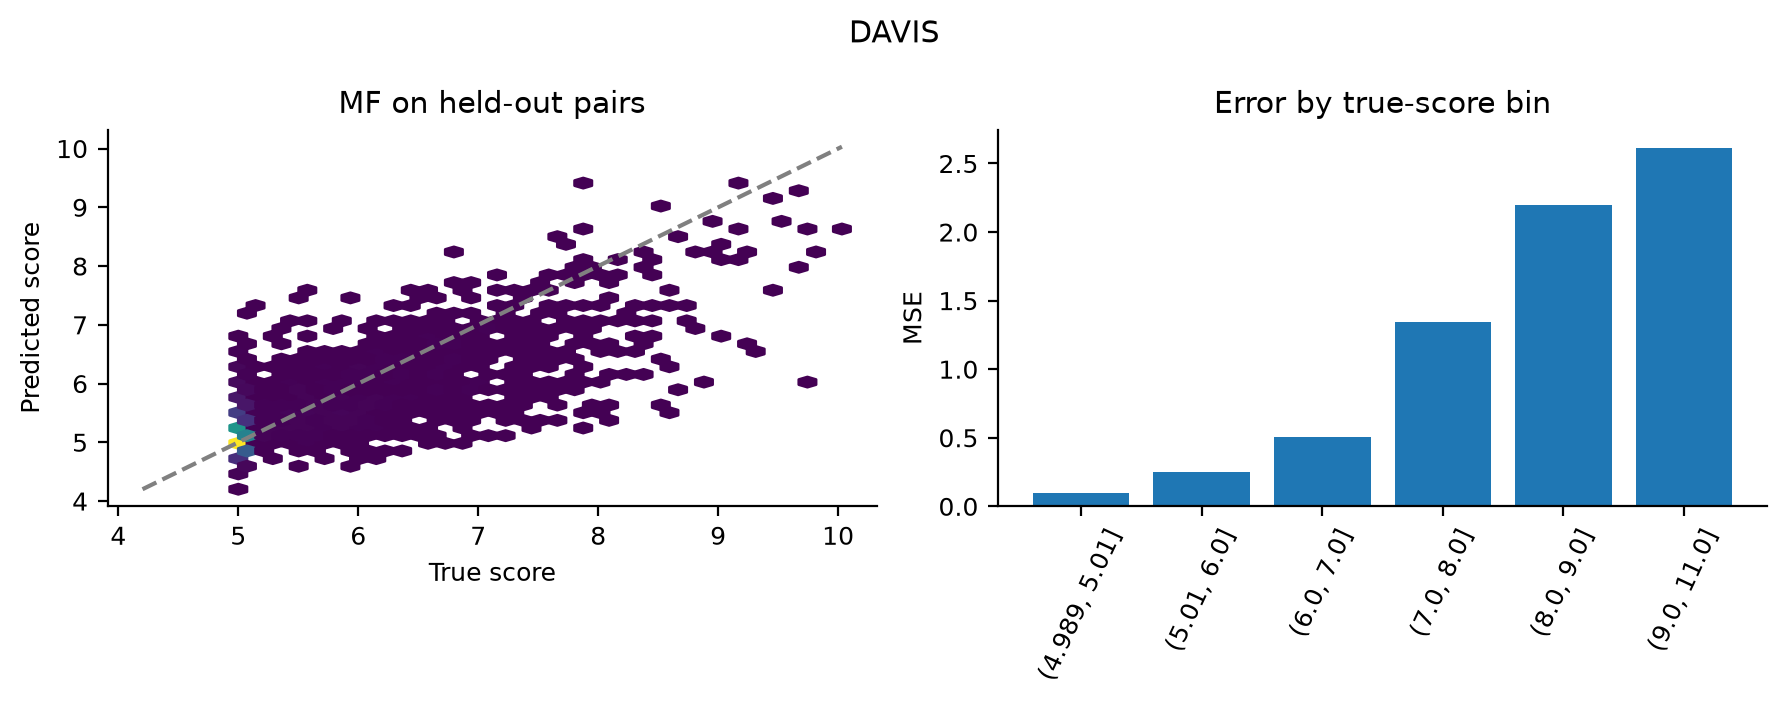

## KIBA

,model,regularization,validation_mse,validation_ci,trial,factors,learning_rate,max_epochs,patience,seed,best_epoch,k,beta,fallback_fraction
11,MF,0.01,0.205505,0.841357,8.0,32.0,0.02,160.0,16.0,2026.0,22.0,NaN,NaN,NaN
9,MF,0.01,0.214602,0.837814,6.0,16.0,0.02,160.0,16.0,2026.0,28.0,NaN,NaN,NaN
19,target_knn,NaN,0.221261,0.842246,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,50.0,0.000507
18,target_knn,NaN,0.221605,0.841680,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10.0,0.000507
20,target_knn,NaN,0.221697,0.842509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,100.0,0.000507
14,target_knn,NaN,0.222038,0.840658,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,10.0,0.000507
15,target_knn,NaN,0.222485,0.840553,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,50.0,0.000507
16,target_knn,NaN,0.223528,0.840557,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,100.0,0.000507


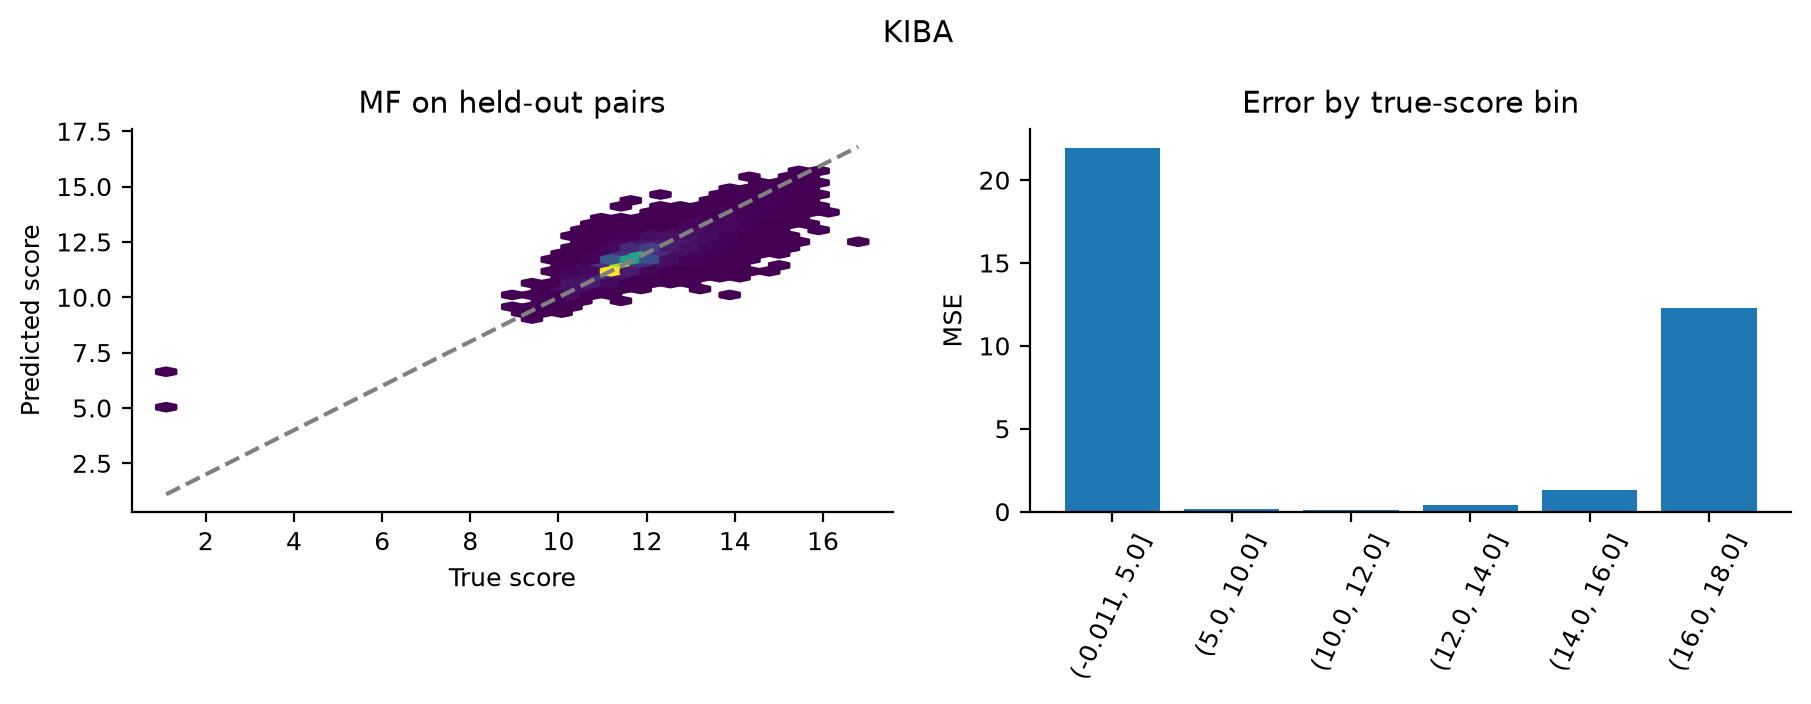

In [3]:
for dataset in ['davis','kiba']:
    frame, parts, manifest = load_splits(dataset, 'task2')
    model = MatrixFactorization.load(ROOT / f'saved_models/{dataset}_cf.npz')
    assert model.metadata['split_sha256'] == manifest['split_sha256']
    saved = read_predictions(ROOT / f'results/predictions/task2_{dataset}_test.csv')
    np.testing.assert_allclose(model.predict(parts['test']), saved.MF, atol=1e-12, rtol=1e-12)
    display(Markdown(f'## {dataset.upper()}'))
    display(pd.read_csv(T / f'task2_{dataset}_tuning.csv').sort_values('validation_mse').head(8))
    display(Image(filename=str(ROOT / f'results/figures/task2_{dataset}_diagnostics.png')))

In [4]:
display(pd.read_csv(T / 'paired_ligand_bootstrap.csv').query("task == 'task2'"))
display(pd.read_csv(T / 'task2_davis_thinning.csv')[['fraction','model','mse','unseen_test_pairs']])

,dataset,task,model,baseline,ligands,replicates,mse_difference,bootstrap_95_low,bootstrap_95_high,seed,split_seed
0,davis,task2,MF,bias_only,68,1000,-0.176210,-0.231615,-0.124834,2026,NaN
6,kiba,task2,MF,bias_only,2068,1000,-0.151888,-0.166051,-0.139052,2026,NaN


,fraction,model,mse,unseen_test_pairs
0,1.00,bias_only,0.432096,0
1,1.00,MF,0.255887,0
2,0.50,bias_only,0.438392,0
3,0.50,MF,0.342233,0
4,0.25,bias_only,0.450397,0
5,0.25,MF,0.437921,0
6,0.10,bias_only,0.491434,31
7,0.10,MF,0.483594,31
8,0.05,bias_only,0.525170,363
9,0.05,MF,0.510343,363


Interpretation and metric conventions: [Task 2 report notes](../results/task2_report_notes.md). CI is concordance; bootstrap intervals are separate. Test data never selected settings.